# Loss Functions for Regression and Classification

<!--<badge>--><a href="https://colab.research.google.com/github/kuennethgroup/ml_in_ms_wt26/blob/main/06_ex/loss_functions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a><!--</badge>-->

## Objectives
- Understand what a loss function is and how it differs from an evaluation metric
- Distinguish between **regression** losses and **classification** losses
- Visualize the most common losses of both families and understand their behavior
- Train scikit-learn models that differ *only* in their loss function and compare the results

## What is a loss function?

A **loss function** $\ell(y, \hat{y})$ measures how bad a single prediction $\hat{y}$ is compared to the true value $y$.
During training, the model parameters $\mathbf{w}$ are chosen to minimize the average loss over the training data:

$$
\mathbf{w}^* = \arg\min_{\mathbf{w}} \frac{1}{N}\sum_{i=1}^{N} \ell\big(y_i, \hat{y}_i(\mathbf{w})\big) \;(+\; \text{regularization})
$$

**Loss vs. metric**
- The *loss* is what the optimizer minimizes. It must be (mostly) differentiable and should be cheap to compute.
- A *metric* is what **we** use to judge the model (e.g., R², accuracy, F1). It does not have to be differentiable.
- Sometimes they coincide (MSE can be both), often they do not (we train a classifier with log loss but report accuracy).

### Regression vs. classification

The type of task determines which loss functions make sense, because the *kind of error* is different:

| | **Regression** | **Classification** |
|---|---|---|
| Target $y$ | continuous number (e.g., band gap in eV) | discrete class (e.g., metal / non-metal) |
| Model output | a real value $\hat{y}$ | a probability $\hat{p}$ for each class |
| What the loss looks at | **residual** $r = y - \hat{y}$ (how far off?) | **predicted probability of the true class** (how sure and correct?) |
| Typical losses | MSE (L2), MAE (L1), Huber | log loss (cross-entropy) |
| Typical metrics | MSE, RMSE, MAE, R² | accuracy, precision/recall, F1, ROC-AUC, log loss |

The notebook has two parts: **Part A** covers regression losses, **Part B** covers classification losses.

In [8]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_regression, make_blobs
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Regression models and metrics
from sklearn.linear_model import LinearRegression, HuberRegressor, QuantileRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Classification models and metrics
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, f1_score, log_loss

sns.set_palette("colorblind")

# A: Regression Loss Functions

In regression, the loss is a function of the **residual** $r = y - \hat{y}$. A residual of zero means a perfect prediction; the larger $|r|$, the larger the loss.
The losses differ in how strongly they punish large residuals:

| Loss | Formula $\ell(r)$ | scikit-learn |
|---|---|---|
| Mean Squared Error (MSE, L2) | $r^2$ | `LinearRegression`, `loss="squared_error"` |
| Mean Absolute Error (MAE, L1) | $\lvert r \rvert$ | `QuantileRegressor(quantile=0.5)`, `loss="absolute_error"` |
| Huber | $\tfrac{1}{2}r^2$ if $\lvert r\rvert \le \delta$, else $\delta\left(\lvert r\rvert - \tfrac{1}{2}\delta\right)$ | `HuberRegressor`, `loss="huber"` |

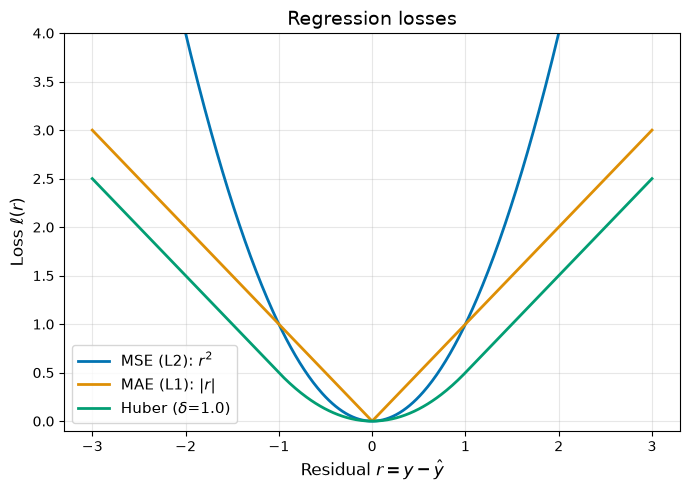

In [9]:
# Residuals r = y - y_hat
r = np.linspace(-3, 3, 500)

delta = 1.0  # Huber transition point

reg_losses = {
    "MSE (L2): $r^2$": r**2,
    "MAE (L1): $|r|$": np.abs(r),
    f"Huber ($\\delta$={delta})": np.where(
        np.abs(r) <= delta, 0.5 * r**2, delta * (np.abs(r) - 0.5 * delta)
    ),
}

fig, ax = plt.subplots(figsize=(7, 5))
for label, values in reg_losses.items():
    ax.plot(r, values, label=label, linewidth=2)

ax.set_xlabel("Residual $r = y - \\hat{y}$", fontsize=12)
ax.set_ylabel("Loss $\\ell(r)$", fontsize=12)
ax.set_title("Regression losses", fontsize=14)
ax.set_ylim(-0.1, 4)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=11)
fig.tight_layout()

1. MSE (L2)
   - Grows quadratically, so a residual twice as large costs four times as much → very sensitive to outliers
   - Smooth and differentiable everywhere
   - The optimal constant prediction is the mean of $y$

2. MAE (L1)
   - Grows linearly → large errors are not over-weighted → robust to outliers
   - Not differentiable at $r = 0$ -> harder for gradient-based optimizers
   - The optimal constant prediction is the median of $y$ -> good for skewed distributions

3. Huber
   - Quadratic (like MSE) for $|r| \le \delta$, linear (like MAE) for $|r| > \delta$
   - Robust to outliers *and* differentiable; $\delta$ controls what counts as an outlier

## A.1 Data

To see the effect of the loss function, we create a simple 1D linear dataset and corrupt a fraction of the training targets with large outliers.
The test set stays clean.

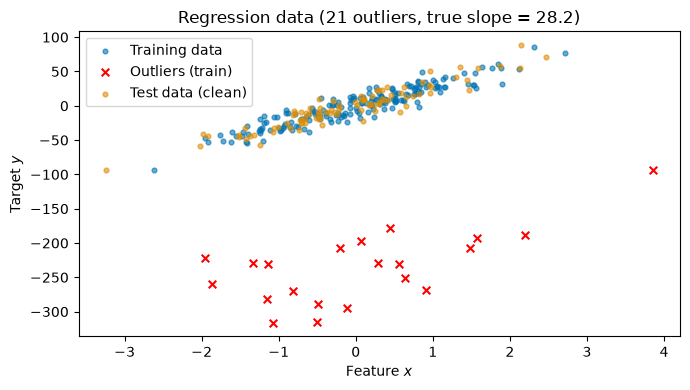

In [10]:
rng = np.random.default_rng(0)

X_reg, y_reg, true_coef = make_regression(
    n_samples=300, n_features=1, noise=10, coef=True, random_state=42
)

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg, test_size=0.3, random_state=42
)

# Corrupt a fraction of the training targets with outliers
outlier_fraction = 0.10
n_outliers = int(outlier_fraction * len(y_reg_train))
outlier_idx = rng.choice(len(y_reg_train), size=n_outliers, replace=False)

y_reg_train = y_reg_train.copy()
y_reg_train[outlier_idx] -= rng.uniform(150, 300, size=n_outliers)

is_outlier = np.zeros(len(y_reg_train), dtype=bool)
is_outlier[outlier_idx] = True

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(X_reg_train[~is_outlier], y_reg_train[~is_outlier], s=12, alpha=0.6, label="Training data")
ax.scatter(X_reg_train[is_outlier], y_reg_train[is_outlier], s=30, marker="x", color="red", label="Outliers (train)")

# no outliers in the test set
ax.scatter(X_reg_test, y_reg_test, s=12, alpha=0.6, label="Test data (clean)")
ax.set_xlabel("Feature $x$")
ax.set_ylabel("Target $y$")
ax.set_title(f"Regression data ({n_outliers} outliers, true slope = {true_coef:.1f})")
ax.legend()
fig.tight_layout()

## A.2 Same model, different loss

All three models below are **linear models** $\hat{y} = w x + b$. The only thing that differs is the loss function that is minimized during training:

| Model | Loss |
|---|---|
| `LinearRegression` | MSE |
| `QuantileRegressor(quantile=0.5)` | MAE (median regression) |
| `HuberRegressor` | Huber |

Any difference in the fitted lines is therefore caused by the loss function alone.

True slope: 28.20


,Loss (model),Fitted slope,Fitted intercept,Test MSE,Test MAE,Test R²
0,MSE (LinearRegression),26.734,-23.489,701.823,24.426,0.244
1,MAE (QuantileRegressor),28.127,-1.296,108.350,7.972,0.883
2,Huber (HuberRegressor),28.140,-1.274,108.230,7.969,0.883


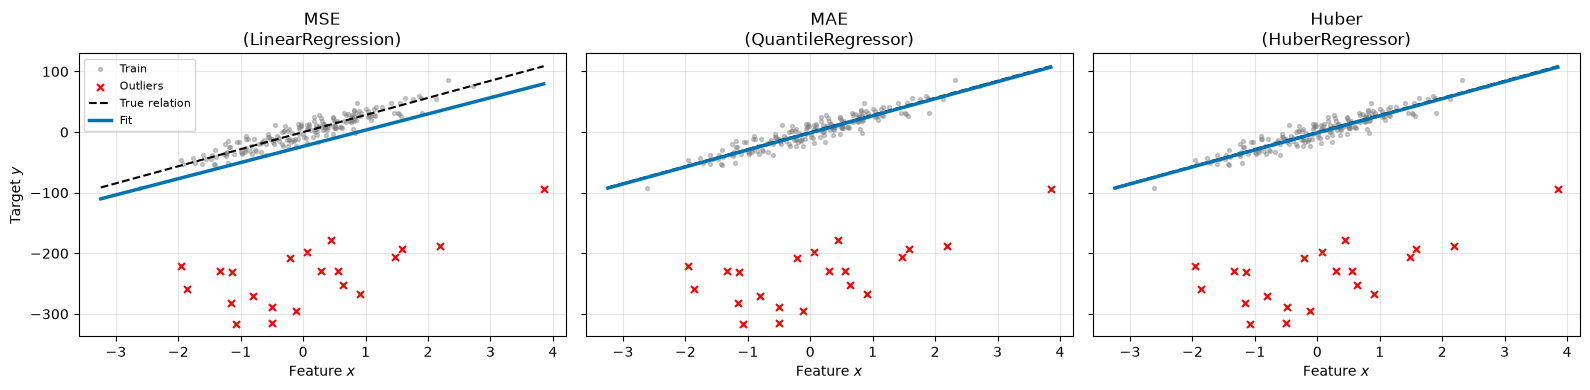

In [11]:
reg_models = {
    "MSE\n(LinearRegression)": LinearRegression(),
    "MAE\n(QuantileRegressor)": QuantileRegressor(quantile=0.5, alpha=0.0),
    "Huber\n(HuberRegressor)": HuberRegressor(epsilon=1.35, alpha=0.0),
}

x_grid = np.linspace(X_reg.min(), X_reg.max(), 100).reshape(-1, 1)

fig, axes = plt.subplots(1, len(reg_models), figsize=(16, 4), sharey=True)
reg_results = []

for ax, (name, model) in zip(axes, reg_models.items()):
    model.fit(X_reg_train, y_reg_train)
    y_pred = model.predict(X_reg_test)

    reg_results.append(
        {
            "Loss (model)": name.replace("\n", " "),
            "Fitted slope": model.coef_.ravel()[0],
            "Fitted intercept": np.ravel(model.intercept_)[0],
            "Test MSE": mean_squared_error(y_reg_test, y_pred),
            "Test MAE": mean_absolute_error(y_reg_test, y_pred),
            "Test R²": r2_score(y_reg_test, y_pred),
        }
    )

    ax.scatter(X_reg_train, y_reg_train, s=8, alpha=0.4, color="gray", label="Train")
    ax.scatter(X_reg_train[is_outlier], y_reg_train[is_outlier], s=25, marker="x", color="red", label="Outliers")
    ax.plot(x_grid, true_coef * x_grid, "k--", linewidth=1.5, label="True relation")
    ax.plot(x_grid, model.predict(x_grid), linewidth=2.5, label="Fit")
    ax.set_title(name)
    ax.set_xlabel("Feature $x$")
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel("Target $y$")
axes[0].legend(fontsize=8)
fig.tight_layout()

print(f"True slope: {true_coef:.2f}")
display(pd.DataFrame(reg_results).round(3))

### Observation

- The MSE fit is pulled towards the outliers: squaring a residual of ~200 gives a huge loss, so the model shifts its whole line towards them (see the intercept) to reduce it. The test R² drops.
- MAE and Huber grow only linearly for large residuals. The outliers still matter, but much less, and these fits stay close to the true relation.
Note that we evaluate all models with the *same* metrics (MSE, MAE, R² on clean test data). The loss used for training and the metric used for evaluation are two separate choices.

Rule of thumb for regression: use MSE for clean data with roughly Gaussian noise; use MAE or Huber when you expect outliers or heavy-tailed noise.

## Exercises

1. Change `outlier_fraction` to `0.0`, `0.05`, and `0.3`. How do the fitted slopes and test metrics of the three models change? At which point does even the Huber regressor break down?
2. Vary the `epsilon` parameter of `HuberRegressor` (e.g., `1.0`, `1.35`, `2`, `5`, `10`). What happens for large `epsilon`, and why?
3. Instead of shifting outliers only downwards, add positive and negative outliers. Does the MSE model still get biased?


# B: Classification Loss Functions

In (binary) classification, the target is a class, not a number. Computing a residual like $y - \hat{y}$ makes little sense (what is class 1 minus class 0?).
Instead, the model predicts a **probability** for each class, and the loss looks at how much probability the model assigns to the **true** class.

What we actually care about is the number of mistakes (i.e., $1 - \text{accuracy}$). However, it is a step function: its gradient is zero almost everywhere, so optimizers cannot use it. We therefore train with a smooth **surrogate loss** instead.

### Log loss (cross-entropy)

For a model that predicts a probability $\hat{p} = P(y = 1 \mid \mathbf{x})$ and labels $y \in \{0, 1\}$, the log loss (binary cross-entropy) reads

$$\ell(y, \hat{p}) = -\big[\, y \log \hat{p} + (1-y) \log(1-\hat{p}) \,\big]$$

Written as a sum over the two classes $k \in \{0, 1\}$, with $y_1 = y$, $y_0 = 1 - y$ and $\hat{p}_1 = \hat{p}$, $\hat{p}_0 = 1 - \hat{p}$:

$$\ell(y, \hat{p}) = -\sum_{k \in \{0, 1\}} y_k \log \hat{p}_k$$

For $K$ classes with one-hot labels $y_k$ and predicted probabilities $\hat{p}_k$ (e.g., from a softmax), this generalizes to the categorical cross-entropy

$$\ell(\mathbf{y}, \hat{\mathbf{p}}) = -\sum_{k=1}^{K} y_k \log \hat{p}_k = -\log \hat{p}_{\text{true class}}$$

For training, the loss is averaged over all $N$ samples (index $i$). For the binary and the categorical case this gives

$$L = -\frac{1}{N}\sum_{i=1}^{N} \big[\, y_i \log \hat{p}_i + (1-y_i) \log(1-\hat{p}_i) \,\big]
\qquad\text{and}\qquad
L = -\frac{1}{N}\sum_{i=1}^{N} \sum_{k=1}^{K} y_{ik} \log \hat{p}_{ik}$$

So the loss only depends on the probability assigned to the true class (others are multiplied by 0 --> they don't contribute to the loss).

- Smooth and never exactly zero: the model always profits from becoming more confident in correct predictions
- Default loss of logistic regression ($\hat{p} = \sigma(\mathbf{w}^T\mathbf{x} + b)$) and of neural network classifiers

       careful: accuracy = 0.80, log loss = 0.415
 overconfident: accuracy = 0.80, log loss = 0.929


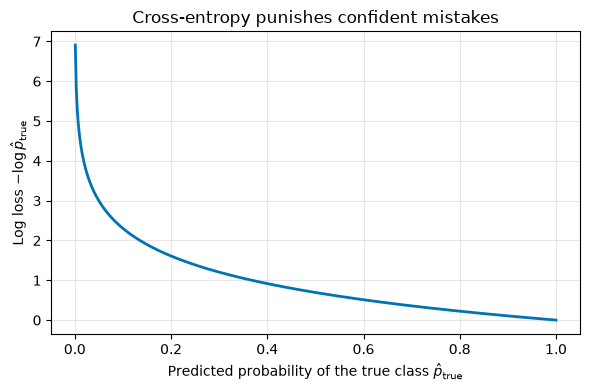

In [12]:
p_true = np.linspace(0.001, 1, 500)  # predicted probability of the true class

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(p_true, -np.log(p_true), linewidth=2)
ax.set_xlabel("Predicted probability of the true class $\\hat{p}_{\\mathrm{true}}$", )
ax.set_ylabel("Log loss $-\\log \\hat{p}_{\\mathrm{true}}$", )
ax.set_title("Cross-entropy punishes confident mistakes", )
ax.grid(True, alpha=0.3)
fig.tight_layout()

# Two classifiers with the SAME accuracy but different confidence
y_true = np.array([1, 1, 1, 0, 0])
p_careful = np.array([0.80, 0.70, 0.40, 0.30, 0.20])  # wrong on sample 3, but unsure
p_overconfident = np.array([0.99, 0.99, 0.01, 0.01, 0.01])  # wrong on sample 3, very sure

for name, p in [("careful", p_careful), ("overconfident", p_overconfident)]:
    acc = accuracy_score(y_true, p > 0.5)
    print(f"{name:>14}: accuracy = {acc:.2f}, log loss = {log_loss(y_true, p):.3f}")

Both classifiers make the same mistake, so their accuracy is identical. The log loss is much larger for the overconfident one, because it assigned only 1 % probability to the true class of the misclassified sample. Example why a loss and a metric measure different things.

## B.1 Data: two overlapping classes with label noise

Create a 2D binary classification dataset with two partly overlapping Gaussian blobs. Also, we flip the labels of a fraction of the samples, which mimics wrongly annotated data.

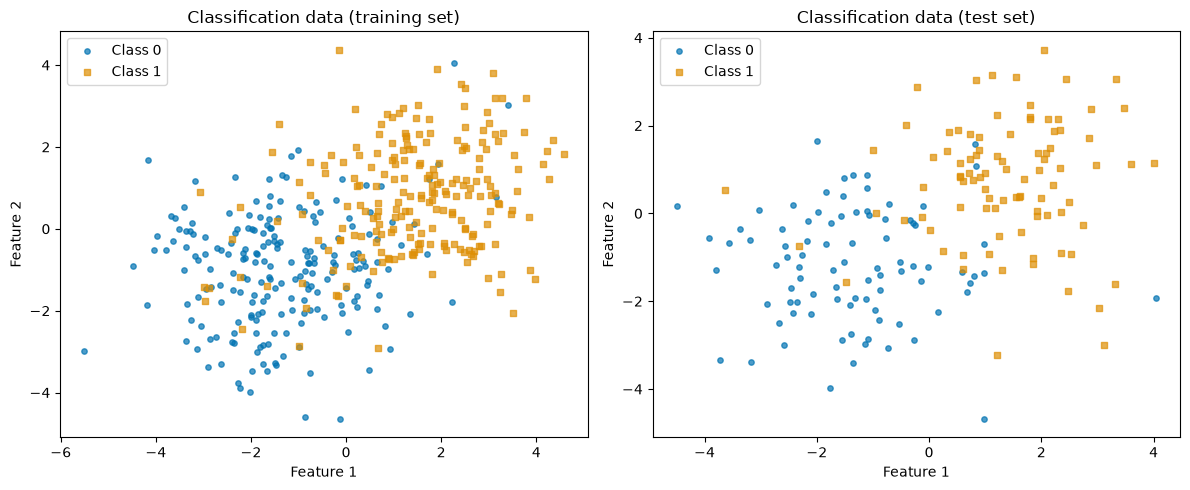

In [13]:
X_clf, y_clf = make_blobs(
    n_samples=600,
    centers=[(-1.5, -1.0), (1.5, 1.0)],
    cluster_std=1.3,
    random_state=7,
)

# Flip a fraction of the labels (label noise)
label_noise = 0.05
flip_idx = rng.choice(len(y_clf), size=int(label_noise * len(y_clf)), replace=False)
y_clf[flip_idx] = 1 - y_clf[flip_idx]

X_clf_train, X_clf_test, y_clf_train, y_clf_test = train_test_split(
    X_clf, y_clf, test_size=0.3, random_state=42, stratify=y_clf
)

fig, (ax1, ax2) = plt.subplots(1,2,figsize=(12,5))
for c, marker in zip([0, 1], ["o", "s"]):
    sel = y_clf_train == c
    ax1.scatter(X_clf_train[sel, 0], X_clf_train[sel, 1], s=15, alpha=0.7, marker=marker, label=f"Class {c}")
for c, marker in zip([0, 1], ["o", "s"]):
    sel = y_clf_test == c
    ax2.scatter(X_clf_test[sel, 0], X_clf_test[sel, 1], s=15, alpha=0.7, marker=marker, label=f"Class {c}")
ax1.set_xlabel("Feature 1")
ax1.set_ylabel("Feature 2")
ax1.set_title("Classification data (training set)")
ax1.legend()
ax2.set_xlabel("Feature 1")
ax2.set_ylabel("Feature 2")
ax2.set_title("Classification data (test set)")
ax2.legend()
fig.tight_layout()

## B.2 Same model, different loss

`SGDClassifier` trains a linear classifier $f(\mathbf{x}) = \mathbf{w}^T\mathbf{x} + b$ with stochastic gradient descent. Its `loss` argument lets us swap the loss function while keeping everything else identical.

- `loss="log_loss"` → logistic regression (the log loss from above)
- `loss="hinge"` → linear support vector machine

The hinge loss comes from support vector machines and are not discussed in detail here. The important difference for us: it is not based on predicted probabilities.

We use a small, adaptive learning rate with averaging so that SGD converges properly. Otherwise, differences caused by the noisy optimizer could be mistaken for effects of the loss function.

We plot the decision boundary ($f(\mathbf{x}) = 0$) of each model.

,Training loss,Test accuracy,Test F1,Test log loss,Has predict_proba
0,log_loss,0.911,0.911,0.293,True
1,hinge,0.911,0.910,NaN,False


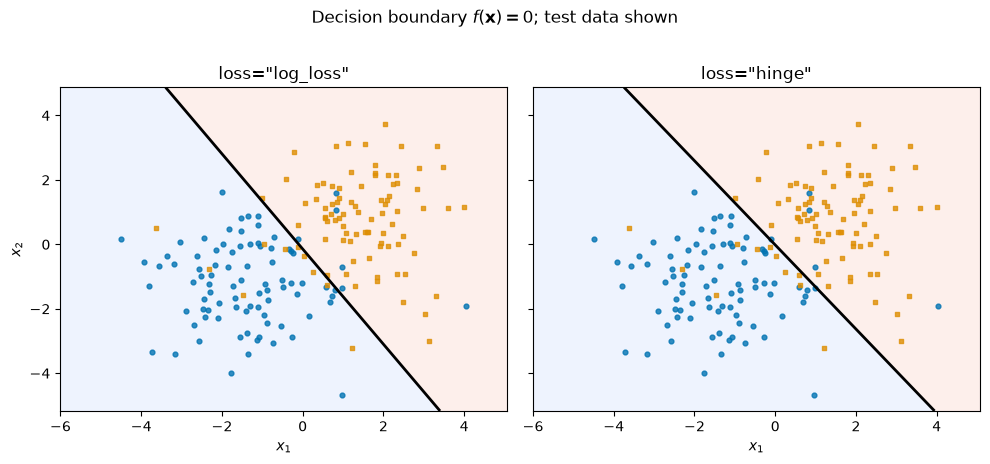

In [14]:
clf_loss_names = ["log_loss", "hinge"]

clf_models = {
    loss: make_pipeline(
        StandardScaler(),
        SGDClassifier(
            loss=loss,
            alpha=1e-3,  # strength of L2 regularization
            learning_rate="adaptive",
            eta0=0.01,
            average=True,  # averaged SGD -> stable, converged solution
            max_iter=5000,
            tol=1e-5,
            random_state=42,
        ),
    )
    for loss in clf_loss_names
}

# Grid for decision function plots
x1_min, x1_max = X_clf[:, 0].min() - 0.5, X_clf[:, 0].max() + 0.5
x2_min, x2_max = X_clf[:, 1].min() - 0.5, X_clf[:, 1].max() + 0.5
xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 300), np.linspace(x2_min, x2_max, 300))
grid = np.c_[xx1.ravel(), xx2.ravel()]

fig, axes = plt.subplots(1, len(clf_models), figsize=(10, 4.5), sharey=True)
clf_results = []

for ax, (loss, model) in zip(axes, clf_models.items()):
    model.fit(X_clf_train, y_clf_train)
    y_pred = model.predict(X_clf_test)

    # Probabilities are only available for losses with a probabilistic interpretation
    if hasattr(model, "predict_proba"):
        test_log_loss = log_loss(y_clf_test, model.predict_proba(X_clf_test))
    else:
        test_log_loss = np.nan

    clf_results.append(
        {
            "Training loss": loss,
            "Test accuracy": accuracy_score(y_clf_test, y_pred),
            "Test F1": f1_score(y_clf_test, y_pred),
            "Test log loss": test_log_loss,
            "Has predict_proba": hasattr(model, "predict_proba"),
        }
    )

    # Decision function f(x) on the grid
    f = model.decision_function(grid).reshape(xx1.shape)
    ax.contourf(xx1, xx2, f > 0, alpha=0.15, cmap="coolwarm")
    ax.contour(xx1, xx2, f, levels=[0], colors="k", linewidths=2)

    for c, marker in zip([0, 1], ["o", "s"]):
        sel = y_clf_test == c
        ax.scatter(X_clf_test[sel, 0], X_clf_test[sel, 1], s=12, alpha=0.8, marker=marker)

    ax.set_title(f'loss="{loss}"')
    ax.set_xlabel("$x_1$")

axes[0].set_ylabel("$x_2$")
fig.suptitle("Decision boundary $f(\\mathbf{x}) = 0$; test data shown", y=1.02)
fig.tight_layout()

display(pd.DataFrame(clf_results).round(3))

### Interpretation

- Both models are linear, so both boundaries are straight lines. 
- On this simple problem they end up at almost the same place, and the accuracies are nearly identical. The choice of classification loss usually matters less for the predicted *labels* than the choice of regression loss does in the presence of outliers.


---
# Summary

| | **Regression** | **Classification** |
|---|---|---|
| Loss depends on | residual $r = y - \hat{y}$ | predicted probability of the true class |
| Default choice | **MSE** | **log loss / cross-entropy** |
| Robust alternative | **MAE**, **Huber** (outliers in $y$) | – |
| Typical metrics | MSE, RMSE, MAE, R² | accuracy, F1, ROC-AUC, log loss |

Key messages:
1. The **task** (continuous target vs. class label) determines the *family* of loss functions.
2. Within a family, the loss determines **how errors of different size are weighted** → robustness to outliers.
3. **Loss ≠ metric**: train with a differentiable loss, evaluate with the metric that matters for your application.

## Exercises


### Part B: Classification
1. Increase the label noise (`label_noise = 0.2`) and move the blob centers closer together. Which losses are most affected?
2. In the "careful vs. overconfident" example, change the probabilities so that both classifiers make **no** mistakes. Which one has the lower log loss now?
3. Replace `make_blobs` with `make_moons(n_samples=600, noise=0.25)`. Why do all linear models fail regardless of the loss? Try `sklearn.svm.SVC(kernel="rbf", probability=True)` (hinge loss + kernel) and `LogisticRegression` on `PolynomialFeatures(degree=3)` (log loss + nonlinear features).

### More
1. Why can't we directly minimize the 0-1 loss (or maximize accuracy) with gradient descent?
2. Your model predicts the band gap of materials, but 2 % of the database entries are known to be wrong. Which loss would you choose, and which metric would you report?